In [70]:
cd /workspace/gkuzmin/prompt_fairness/prompt-fairness/

/workspace/gkuzmin/prompt_fairness/prompt-fairness


In [150]:
import os
import json
import numpy as np
import pandas as pd

from tqdm import tqdm
from collections import Counter
# from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectFromModel
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler


import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package punkt to /home/jovyan/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/jovyan/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/jovyan/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/jovyan/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to /home/jovyan/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Read the files

In [151]:
root_folder = "./annotation_artefacts/final_annotator_objects"

rows = []

# walk through all subdirectories and files
for subdir, _, files in os.walk(root_folder):
    for file in files:
        if file.endswith(".json"):  # only JSON files
            file_path = os.path.join(subdir, file)
            with open(file_path, 'r', encoding='utf-8') as f:
                data = json.load(f)
            
            # extract common fields
            # annot_id = data.get("id")
            profile = data.get("profile", {})

            # answers are a dict of dicts
            answers = data.get("answers", {})
            for q_key, answer_obj in answers.items():
                # skip if answer is None or empty string
                answer_text = answer_obj.get("answer")
                if answer_text is None or (isinstance(answer_text, str) and answer_text.strip() == ""):
                    continue  # skip this one

                row = {}
                # row["id"] = annot_id

                # add profile columns
                for k, v in profile.items():
                    row[k] = v

                # add answer fields
                row["answer"] = answer_obj.get("answer")
                row["sentence_type"] = answer_obj.get("sentence_type")
                row["grammaticality"] = answer_obj.get("grammaticality")

                rows.append(row)

df = pd.DataFrame(rows)

df.sample(2)
# df.to_csv("annotations_flattened.csv", index=False)

,employment_sector,race,education,sex,age,language,nationality_group,answer,sentence_type,grammaticality
208,Engineering-STEM,Asian,Postgraduate,male,18-30,L1,None,Using your understanding of natural language p...,imperative,correct
693,Engineering-STEM,None,Highschool,male,31-40,L1,Europe,"List all words, noun phrases, and pronouns in ...",imperative,correct


# Extract Text Features

In [152]:
def extract_text_features(text):
    if not isinstance(text, str) or text.strip() == "":
        # return NaNs or zeros for empty values
        return pd.Series({
            "self_ref_freq": np.nan,
            "num_words": 0,
            "num_chars": 0,
            "num_capital_words": 0,
            "num_stopwords": 0,
            "num_exclamation": 0,
            "num_question": 0,
            "num_nouns": 0,
            "num_verbs": 0,
            "num_adjectives": 0,
            "num_adverbs": 0,
            "num_pronouns": 0,
            "ttr": np.nan,
            "avg_word_length": np.nan,
            "num_short_words": 0,
            "num_long_words": 0,
            "num_numeric": 0
        })

    # Tokenize
    tokens = word_tokenize(text)
    words = [w for w in tokens if w.isalpha() or w.isalnum()]  # keep alphanumeric
    num_words = len(words)
    if num_words == 0:
        num_words = 1  # avoid division by zero

    # Self-reference pronouns
    self_refs = {"i", "me", "my", "mine", "myself",
                 "we", "us", "our", "ours", "ourselves",
                 "team"} # add more if we have any more idea
    self_ref_count = sum(1 for w in words if w.lower() in self_refs)
    self_ref_freq = self_ref_count / num_words

    # Characters (excluding spaces)
    num_chars = len(text.replace(" ", ""))

    # Capital words (fully uppercase and length>1)
    num_capital_words = sum(1 for w in words if w.isupper() and len(w) > 1)

    # Stopwords
    num_stopwords = sum(1 for w in words if w.lower() in stop_words)

    # Punctuation marks
    num_exclamation = text.count("!")
    num_question = text.count("?")

    # POS tagging
    tagged = nltk.pos_tag(words)
    pos_counts = Counter(tag for _, tag in tagged)
    # Map Penn Treebank POS to broad categories
    num_nouns = sum(pos_counts[t] for t in pos_counts if t.startswith('NN'))
    num_verbs = sum(pos_counts[t] for t in pos_counts if t.startswith('VB'))
    num_adjectives = sum(pos_counts[t] for t in pos_counts if t.startswith('JJ'))
    num_adverbs = sum(pos_counts[t] for t in pos_counts if t.startswith('RB'))
    num_pronouns = sum(pos_counts[t] for t in pos_counts if t in {'PRP','PRP$','WP','WP$'})

    # Type-Token Ratio (TTR)
    unique_words = len(set(w.lower() for w in words))
    ttr = unique_words / num_words

    # Average word length
    avg_word_length = np.mean([len(w) for w in words])

    # Short and long words
    num_short_words = sum(1 for w in words if len(w) <= 3)
    num_long_words = sum(1 for w in words if len(w) >= 7)

    # Numeric tokens
    num_numeric = sum(1 for w in tokens if any(ch.isdigit() for ch in w))

    return pd.Series({
        "self_ref_freq": self_ref_freq,
        "num_words": num_words,
        "num_chars": num_chars,
        "num_capital_words": num_capital_words,
        "num_stopwords": num_stopwords,
        "num_exclamation": num_exclamation,
        "num_question": num_question,
        "num_nouns": num_nouns,
        "num_verbs": num_verbs,
        "num_adjectives": num_adjectives,
        "num_adverbs": num_adverbs,
        "num_pronouns": num_pronouns,
        "ttr": ttr,
        "avg_word_length": avg_word_length,
        "num_short_words": num_short_words,
        "num_long_words": num_long_words,
        "num_numeric": num_numeric
    })


In [153]:
def extract_text_features_updated(text):
    if not isinstance(text, str) or text.strip() == "":
        # return NaNs or zeros for empty values
        return pd.Series({
            "self_ref_freq": np.nan,
            "num_words": 0,
            "ratio_capital_words": 0,
            "ratio_stopwords": 0,
            "ratio_exclamation": 0,
            "ratio_question": 0,
            "ratio_nouns": 0,
            "ratio_verbs": 0,
            "ratio_adjectives": 0,
            "ratio_adverbs": 0,
            "ratio_pronouns": 0,
            "ttr": np.nan,
            "avg_word_length": np.nan,
            "ratio_short_words": 0,
            "ratio_long_words": 0,
            "ratio_numeric": 0
        })

    # Tokenize
    tokens = word_tokenize(text)
    words = [w for w in tokens if w.isalpha() or w.isalnum()]  # keep alphanumeric
    num_words = len(words)
    if num_words == 0:
        num_words = 1  # avoid division by zero

    # Self-reference pronouns
    self_refs = {"i", "me", "my", "mine", "myself",
                 "we", "us", "our", "ours", "ourselves",
                 "team"} # add more if we have any more idea
    self_ref_count = sum(1 for w in words if w.lower() in self_refs)
    self_ref_freq = self_ref_count / num_words

    # Characters (excluding spaces)
    num_chars = len(text.replace(" ", ""))

    # Capital words (fully uppercase and length>1)
    num_capital_words = sum(1 for w in words if w.isupper() and len(w) > 1) / num_words

    # Stopwords
    num_stopwords = sum(1 for w in words if w.lower() in stop_words) / num_words

    # Punctuation marks
    num_exclamation = text.count("!") / num_words
    num_question = text.count("?") / num_words

    # POS tagging
    tagged = nltk.pos_tag(words)
    pos_counts = Counter(tag for _, tag in tagged)
    # Map Penn Treebank POS to broad categories
    num_nouns = sum(pos_counts[t] for t in pos_counts if t.startswith('NN')) / num_words
    num_verbs = sum(pos_counts[t] for t in pos_counts if t.startswith('VB')) / num_words
    num_adjectives = sum(pos_counts[t] for t in pos_counts if t.startswith('JJ')) / num_words
    num_adverbs = sum(pos_counts[t] for t in pos_counts if t.startswith('RB')) / num_words
    num_pronouns = sum(pos_counts[t] for t in pos_counts if t in {'PRP','PRP$','WP','WP$'}) / num_words

    # Type-Token Ratio (TTR)
    unique_words = len(set(w.lower() for w in words))
    ttr = unique_words / num_words

    # Average word length
    avg_word_length = np.mean([len(w) for w in words])

    # Short and long words
    num_short_words = sum(1 for w in words if len(w) <= 3) / num_words
    num_long_words = sum(1 for w in words if len(w) >= 7) / num_words

    # Numeric tokens
    num_numeric = sum(1 for w in tokens if any(ch.isdigit() for ch in w)) / num_words

    return pd.Series({
        "self_ref_freq": self_ref_freq,
        "num_words": num_words,
        #"num_chars": num_chars,
        "ratio_capital_words": num_capital_words,
        "ratio_stopwords": num_stopwords,
        "ratio_exclamation": num_exclamation,
        "ratio_question": num_question,
        "ratio_nouns": num_nouns,
        "ratio_verbs": num_verbs,
        "ratio_adjectives": num_adjectives,
        "ratio_adverbs": num_adverbs,
        "ratio_pronouns": num_pronouns,
        "ttr": ttr,
        "avg_word_length": avg_word_length,
        #"ratio_short_words": num_short_words,
        #"ratio_long_words": num_long_words,
        "ratio_numeric": num_numeric
    })

In [154]:
features_df = df['answer'].apply(extract_text_features_updated)
df = pd.concat([df, features_df], axis=1)

In [155]:
df.sample(2)

,employment_sector,race,education,sex,age,language,nationality_group,answer,sentence_type,grammaticality,...,ratio_exclamation,ratio_question,ratio_nouns,ratio_verbs,ratio_adjectives,ratio_adverbs,ratio_pronouns,ttr,avg_word_length,ratio_numeric
2526,Health-STEM,Black,Postgraduate,female,41-50,L1,North America,Write a [PASSAGE] and [QUESTION] related to th...,imperative,correct,...,0.0,0.000000,0.296296,0.259259,0.037037,0.037037,0.000000,0.777778,5.259259,0.0
2591,Engineering-STEM,None,Postgraduate,female,41-50,None,Europe,what were the most significant acchivements of...,interrogative,incorrect,...,0.0,0.066667,0.333333,0.133333,0.066667,0.066667,0.066667,0.933333,5.200000,0.0


In [156]:
#df

In [157]:
features_df.corr()

,self_ref_freq,num_words,ratio_capital_words,ratio_stopwords,ratio_exclamation,ratio_question,ratio_nouns,ratio_verbs,ratio_adjectives,ratio_adverbs,ratio_pronouns,ttr,avg_word_length,ratio_numeric
self_ref_freq,1.000000,0.522928,-0.214713,0.268917,0.211693,-0.156485,-0.294321,0.203932,-0.102965,0.223760,0.579663,-0.216623,-0.370371,-0.098635
num_words,0.522928,1.000000,-0.320885,0.197668,0.185509,-0.234290,-0.303071,0.178362,-0.107077,0.548611,0.234622,-0.712225,-0.513187,-0.098911
ratio_capital_words,-0.214713,-0.320885,1.000000,-0.342498,-0.063607,-0.047211,0.275677,0.050726,-0.015431,-0.175076,-0.295162,0.245309,0.455522,0.442400
ratio_stopwords,0.268917,0.197668,-0.342498,1.000000,0.026687,0.189303,-0.513630,0.036969,-0.160028,0.136398,0.514836,-0.207058,-0.553208,-0.129270
ratio_exclamation,0.211693,0.185509,-0.063607,0.026687,1.000000,-0.070830,-0.005855,-0.016343,-0.046110,0.085274,0.079032,-0.106615,-0.075537,-0.008896
ratio_question,-0.156485,-0.234290,-0.047211,0.189303,-0.070830,1.000000,0.038512,0.062990,0.024315,-0.117898,0.220904,0.275273,0.014856,-0.068047
ratio_nouns,-0.294321,-0.303071,0.275677,-0.513630,-0.005855,0.038512,1.000000,-0.450482,-0.345786,-0.330287,-0.274697,0.249437,0.407247,0.042929
ratio_verbs,0.203932,0.178362,0.050726,0.036969,-0.016343,0.062990,-0.450482,1.000000,-0.129608,0.148182,0.181075,-0.064955,-0.077176,-0.027688
ratio_adjectives,-0.102965,-0.107077,-0.015431,-0.160028,-0.046110,0.024315,-0.345786,-0.129608,1.000000,-0.031807,-0.232931,0.152157,0.195441,-0.041321
ratio_adverbs,0.223760,0.548611,-0.175076,0.136398,0.085274,-0.117898,-0.330287,0.148182,-0.031807,1.000000,0.087241,-0.486805,-0.294317,-0.094659


In [161]:
# save back to json files to build plots and tables
feats_to_add = [
    "num_words",
    "num_short_words",
    "num_chars",
    "num_stopwords",
    "num_nouns",
    "num_pronouns",
    "num_exclamation",
    "num_long_words",
]
# v2
feats_to_add = [
    "ratio_exclamation",
    "ttr",
    "ratio_pronouns",
    "ratio_adjectives",
    "ratio_nouns",
    "num_words",
    #"sentence_type",
    "ratio_capital_words",
    #"grammaticality",
    "ratio_question",
]

In [162]:
root_folder = "./annotation_artefacts/final_annotator_objects"
save_folder = "./annotation_artefacts/final_annotator_objects_with_feats_v2"

rows = []

# walk through all subdirectories and files
for subdir, _, files in os.walk(root_folder):
    for file in files:
        if file.endswith(".json"):  # only JSON files
            file_path = os.path.join(subdir, file)
            with open(file_path, 'r', encoding='utf-8') as f:
                data = json.load(f)
            
            # extract common fields
            # annot_id = data.get("id")
            profile = data.get("profile", {})

            # answers are a dict of dicts
            answers = data.get("answers", {})
            for q_key, answer_obj in answers.items():
                # skip if answer is None or empty string
                answer_text = answer_obj.get("answer")
                if answer_text is None or (isinstance(answer_text, str) and answer_text.strip() == ""):
                    continue  # skip this one

                row = {}
                # row["id"] = annot_id

                # add profile columns
                for k, v in profile.items():
                    row[k] = v

                # add answer fields
                row["answer"] = answer_obj.get("answer")
                row["sentence_type"] = answer_obj.get("sentence_type")
                row["grammaticality"] = answer_obj.get("grammaticality")

                rows.append(row)
            # now map the json back to df, extract feats and save back to json
            pass
            save_subdir = subdir.replace(root_folder, save_folder)
            save_path = os.path.join(save_subdir, file)
            os.makedirs(save_subdir, exist_ok=True)
            #print(data.keys())
            #print(data["answers"].keys())
            for key in data["answers"].keys():
                buf_text = data["answers"][key]["answer"]
                text_feats = extract_text_features_updated(buf_text)
                for feat in feats_to_add:
                    data["answers"][key][feat] = text_feats[feat]
                #print(data["answers"][key])
            with open(save_path, 'w', encoding='utf-8') as f:
                json.dump(data, f)

            #break
        #break
    #break

In [113]:
df.columns

Index(['employment_sector', 'race', 'education', 'sex', 'age', 'language',
       'nationality_group', 'answer', 'sentence_type', 'grammaticality',
       'self_ref_freq', 'num_words', 'num_chars', 'num_capital_words',
       'num_stopwords', 'num_exclamation', 'num_question', 'num_nouns',
       'num_verbs', 'num_adjectives', 'num_adverbs', 'num_pronouns', 'ttr',
       'avg_word_length', 'num_short_words', 'num_long_words', 'num_numeric',
       'self_ref_freq', 'num_words', 'num_chars', 'ratio_capital_words',
       'ratio_stopwords', 'ratio_exclamation', 'ratio_question', 'ratio_nouns',
       'ratio_verbs', 'ratio_adjectives', 'ratio_adverbs', 'ratio_pronouns',
       'ttr', 'avg_word_length', 'ratio_short_words', 'ratio_long_words',
       'ratio_numeric', 'self_ref_freq', 'num_words', 'num_chars',
       'ratio_capital_words', 'ratio_stopwords', 'ratio_exclamation',
       'ratio_question', 'ratio_nouns', 'ratio_verbs', 'ratio_adjectives',
       'ratio_adverbs', 'ratio_pronouns

# Prepare The Dataset

In [122]:
from copy import deepcopy

df_2 = deepcopy(df)

In [123]:
# label encode and normalize
special_cols = ['employment_sector', 'race', 'education', 
                'sex', 'age', 'language', 'nationality_group']

label_mappings = {}
for col in special_cols:
    if col in df_2.columns:
        le = LabelEncoder()
        df_2[col] = le.fit_transform(df_2[col].astype(str))
        label_mappings[col] = {class_: int(code) for class_, code in zip(le.classes_, le.transform(le.classes_))}

ignore_cols = ['answer']  
other_cols = [col for col in df_2.columns if col not in special_cols + ignore_cols]
cat_cols = [col for col in other_cols if df_2[col].dtype == 'object']
for col in cat_cols:
    le = LabelEncoder()
    df_2[col] = le.fit_transform(df_2[col].astype(str))

num_cols = [col for col in df_2.columns if col != 'answer' and col not in special_cols]
scaler = MinMaxScaler()
df_2[num_cols] = scaler.fit_transform(df_2[num_cols])

In [124]:
df_2.sample(2)

,employment_sector,race,education,sex,age,language,nationality_group,answer,sentence_type,grammaticality,...,ratio_exclamation,ratio_question,ratio_nouns,ratio_verbs,ratio_adjectives,ratio_adverbs,ratio_pronouns,ttr,avg_word_length,ratio_numeric
696,0,2,1,1,1,0,2,Identify wording in the following text [TEXT] ...,0.5,1.0,...,0.000000,0.0,0.327243,0.325581,0.139535,0.093023,0.170543,0.581395,0.423553,0.000000
715,1,1,2,1,1,0,0,"Hello everyone, my name is john, and I’m a sof...",0.5,0.0,...,0.050955,0.0,0.208371,0.433121,0.127389,0.280255,0.373673,0.350318,0.290554,0.019108


# Find the top-5 features for each categories

In [125]:
special_cols = ['employment_sector', 'race', 'education', 'sex', 'age', 'language', 'nationality_group']

X = df_2.drop(columns=special_cols + ['answer'])

In [126]:
def get_top_features(X, y, top_k=5):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = LinearSVC(random_state=42, max_iter=5000)
    clf.fit(X_scaled, y)

    # absolute value of coefficients indicates importance
    coef = np.abs(clf.coef_)
    if len(coef.shape) == 1:
        importance = coef
    else:
        importance = coef.mean(axis=0)

    feature_importance = pd.Series(importance, index=X.columns)
    return feature_importance.sort_values(ascending=False).head(top_k)

def get_top_features_sfm(X, y, top_k=5, random_state=42, threshold='median'):
    """
    Returns the top_k features selected by SelectFromModel using LinearSVC.
    
    X : pd.DataFrame of features
    y : pd.Series target
    top_k : int, number of top features to return
    threshold : str or float, threshold for SelectFromModel ('median', 'mean', or float value)
    """
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = LinearSVC(random_state=random_state, max_iter=5000)
    clf.fit(X_scaled, y)

    sfm = SelectFromModel(clf, threshold=threshold, prefit=True)
    selected_features = X.columns[sfm.get_support()]

    coefs = pd.Series(abs(clf.coef_).mean(axis=0), index=X.columns)
    top_features = coefs[selected_features].sort_values(ascending=False).head(top_k)
    
    return top_features

def get_top_features_sfm_2(X, y, top_k=5, random_state=42):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = LinearSVC(random_state=random_state, max_iter=5000)
    clf.fit(X_scaled, y)

    # take absolute mean of coefficients across classes
    coefs = pd.Series(abs(clf.coef_).mean(axis=0), index=X.columns)
    top_features = coefs.sort_values(ascending=False).head(top_k)
    
    return top_features, X_scaled


def get_top_features_rf(X, y, top_k=5, random_state=42, threshold='median'):
    """
    Returns the top_k features selected by SelectFromModel using LinearSVC.
    
    X : pd.DataFrame of features
    y : pd.Series target
    top_k : int, number of top features to return
    threshold : str or float, threshold for SelectFromModel ('median', 'mean', or float value)
    """
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    clf = RandomForestClassifier(random_state=random_state, n_estimators=500)
    clf.fit(X_scaled, y)

    feature_importance = pd.Series(clf.feature_importances_, index=X.columns)
    top_features = feature_importance.sort_values(ascending=False).head(top_k)
    
    return top_features

In [127]:
top_features_dict = {}

for target in tqdm(special_cols):
    y = df_2[target]
    top_feats, X_scaled = get_top_features_sfm_2(X, y, top_k=5)
    top_features_dict[target] = top_feats
    # print(f"Top 5 features for {target}:\n{top_feats}\n")

100%|██████████| 7/7 [00:00<00:00, 94.54it/s]


In [139]:
feats_names = [
    "num_words",
    "num_short_words",
    "num_chars",
    "num_stopwords",
    "num_nouns",
    "num_pronouns",
    "num_exclamation",
    "num_long_words",
]

In [140]:
scaled_X = pd.DataFrame(X_scaled, columns=[col for col in df_2.columns if col not in special_cols + ['answer']])

In [141]:
scaled_X.corr()

,sentence_type,grammaticality,self_ref_freq,num_words,ratio_capital_words,ratio_stopwords,ratio_exclamation,ratio_question,ratio_nouns,ratio_verbs,ratio_adjectives,ratio_adverbs,ratio_pronouns,ttr,avg_word_length,ratio_numeric
sentence_type,1.000000,0.056490,-0.133717,-0.144338,-0.078163,0.248472,-0.067816,0.622550,-0.022300,0.016108,-0.000470,-0.097573,0.258073,0.223965,-0.011636,-0.065480
grammaticality,0.056490,1.000000,-0.005829,-0.090218,-0.098439,0.099420,0.018150,-0.001383,0.001928,-0.049375,0.023654,-0.045562,0.084526,0.109521,-0.011119,-0.065484
self_ref_freq,-0.133717,-0.005829,1.000000,0.522928,-0.214713,0.268917,0.211693,-0.156485,-0.294321,0.203932,-0.102965,0.223760,0.579663,-0.216623,-0.370371,-0.098635
num_words,-0.144338,-0.090218,0.522928,1.000000,-0.320885,0.197668,0.185509,-0.234290,-0.303071,0.178362,-0.107077,0.548611,0.234622,-0.712225,-0.513187,-0.098911
ratio_capital_words,-0.078163,-0.098439,-0.214713,-0.320885,1.000000,-0.342498,-0.063607,-0.047211,0.275677,0.050726,-0.015431,-0.175076,-0.295162,0.245309,0.455522,0.442400
ratio_stopwords,0.248472,0.099420,0.268917,0.197668,-0.342498,1.000000,0.026687,0.189303,-0.513630,0.036969,-0.160028,0.136398,0.514836,-0.207058,-0.553208,-0.129270
ratio_exclamation,-0.067816,0.018150,0.211693,0.185509,-0.063607,0.026687,1.000000,-0.070830,-0.005855,-0.016343,-0.046110,0.085274,0.079032,-0.106615,-0.075537,-0.008896
ratio_question,0.622550,-0.001383,-0.156485,-0.234290,-0.047211,0.189303,-0.070830,1.000000,0.038512,0.062990,0.024315,-0.117898,0.220904,0.275273,0.014856,-0.068047
ratio_nouns,-0.022300,0.001928,-0.294321,-0.303071,0.275677,-0.513630,-0.005855,0.038512,1.000000,-0.450482,-0.345786,-0.330287,-0.274697,0.249437,0.407247,0.042929
ratio_verbs,0.016108,-0.049375,0.203932,0.178362,0.050726,0.036969,-0.016343,0.062990,-0.450482,1.000000,-0.129608,0.148182,0.181075,-0.064955,-0.077176,-0.027688


# Viz

In [128]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [129]:
plot_data = []

for target, features in top_features_dict.items():
    features_sorted = features[features > 0].sort_values(ascending=False).head(5)
    for feature, importance in features_sorted.items():
        plot_data.append({
            "Target": target,
            "Feature": feature,
            "Importance": importance
        })

plot_df = pd.DataFrame(plot_data)

targets = plot_df['Target'].unique()
num_targets = len(targets)

In [130]:
plot_df

,Target,Feature,Importance
0,employment_sector,ratio_exclamation,0.086076
1,employment_sector,ttr,0.080720
2,employment_sector,ratio_pronouns,0.054185
3,employment_sector,ratio_adjectives,0.052540
4,employment_sector,ratio_nouns,0.049857
5,race,ratio_exclamation,0.197545
6,race,num_words,0.119931
7,race,ttr,0.113388
8,race,sentence_type,0.068300
9,race,ratio_nouns,0.063754


In [131]:
list(plot_df.groupby("Feature"))

[('grammaticality',
         Target         Feature  Importance
  12  education  grammaticality    0.047478),
 ('num_words',
                 Target    Feature  Importance
  6                race  num_words    0.119931
  21                age  num_words    0.168290
  26           language  num_words    0.156701
  31  nationality_group  num_words    0.100369),
 ('ratio_adjectives',
                Target           Feature  Importance
  3  employment_sector  ratio_adjectives     0.05254),
 ('ratio_capital_words',
         Target              Feature  Importance
  11  education  ratio_capital_words    0.049863),
 ('ratio_exclamation',
                 Target            Feature  Importance
  0   employment_sector  ratio_exclamation    0.086076
  5                race  ratio_exclamation    0.197545
  20                age  ratio_exclamation    0.218332
  25           language  ratio_exclamation    0.249810
  30  nationality_group  ratio_exclamation    0.187883),
 ('ratio_nouns',
           

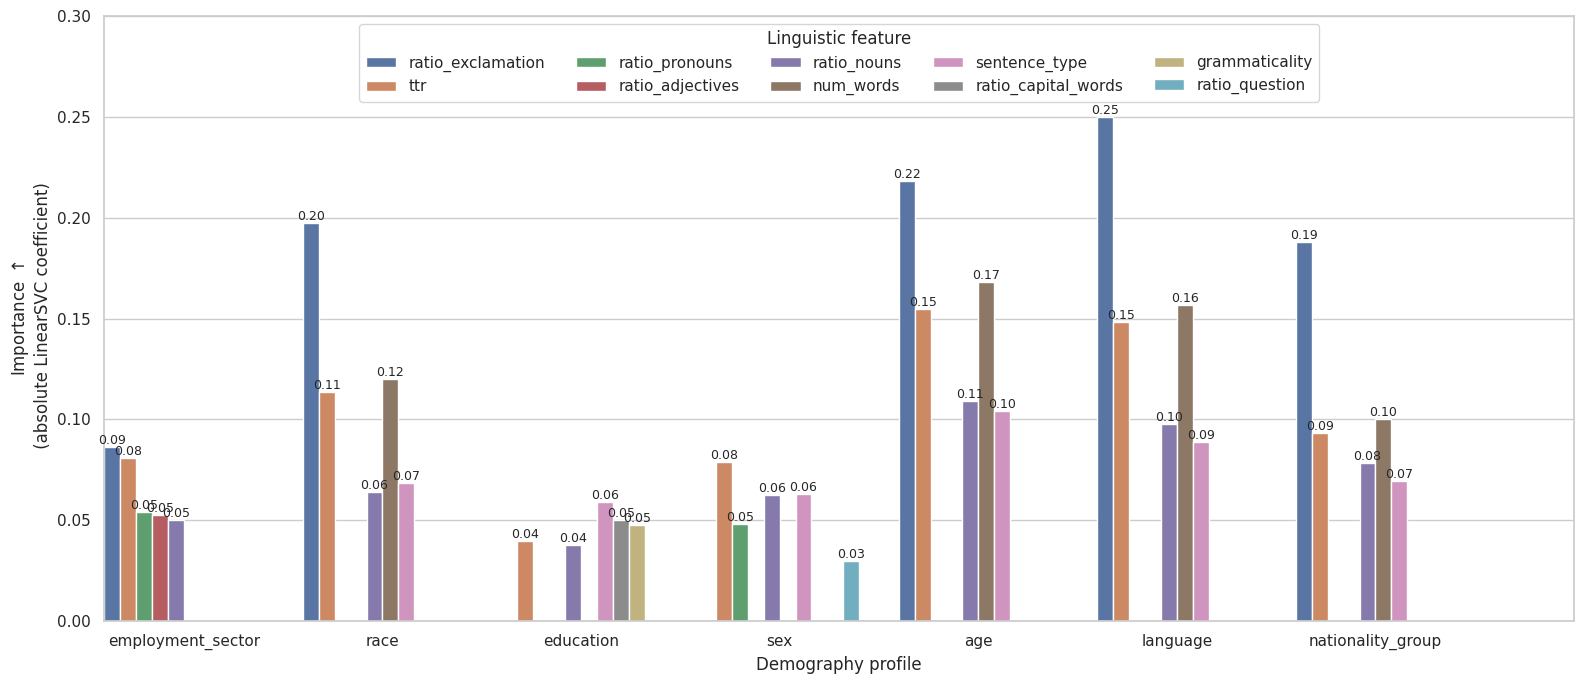

In [136]:
plt.figure(figsize=(16, 7))
# 5 7 2 1 7 4 6 1 1 1
# most common - ratio exclamations, ttr, ratio_nouns, num_words, sentence_type
ax = sns.barplot(
    data=plot_df,
    x="Target",
    y="Importance",
    hue="Feature",
    dodge=True
)

# Annotate bars with importance values
for p in ax.patches:
    height = p.get_height()
    if height > 0: 
        ax.annotate(
            f"{height:.2f}", 
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, rotation=0
        )

#plt.xticks()
#plt.title("Top-5 linguistic features per demography profile (Non-zero only)")
plt.ylabel("Importance $\\uparrow$\n (absolute LinearSVC coefficient)")
plt.xlabel("Demography profile")
plt.ylim(0, 0.3)
plt.xlim(-0.4, 7.)

plt.legend(title="Linguistic feature", loc='upper center', ncol=5)
plt.tight_layout()

plt.show()

<Figure size 1600x700 with 0 Axes>

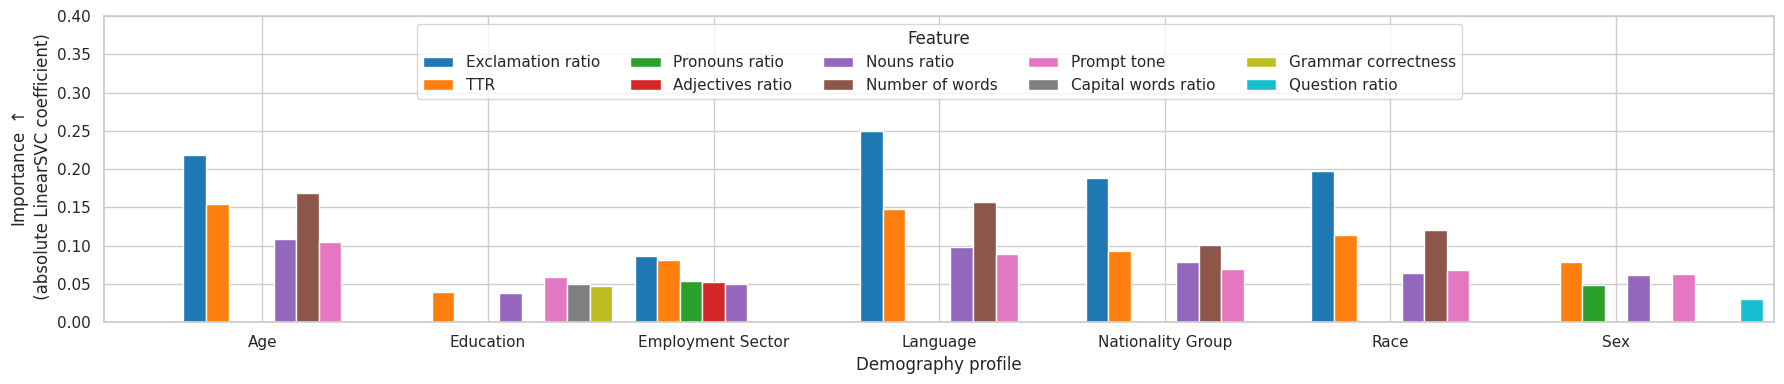

In [163]:
plt.figure(figsize=(16, 7))

# Sort by importance within each target
plot_df = plot_df.sort_values(['Target', 'Importance'], ascending=[True, False])



profile_names = [
    "Employment Sector",
    "Race",
    "Education",
    "Sex",
    "Age",
    "Language",
    "Nationality Group",
]
profile_names = [
    "Age",
    "Education",
    "Employment Sector",
    "Language",
    "Nationality Group",
    "Race",
    "Sex",
]
profiles = [
    "age",
    "education",
    "employment_sector",
    "language",
    "nationality_group",
    "race",
    "sex",
]
feats_names = [
    "num_words",
    "num_short_words",
    "num_chars",
    "num_stopwords",
    "num_nouns",
    "num_pronouns",
    "num_exclamation",
    "num_long_words",
]
feats_display_names = [
    "Number of\nwords",
    "Number of\nshort words",
    "Number of\ncharacters",
    "Number of\nstopwords",
    "Number of\nnouns",
    "Number of\npronouns",
    "Number of\nexclamation",
    "Number of\nlong words",
]

# v2 

feats_names = [
    "ratio_exclamation",
    "ttr",
    "ratio_pronouns",
    "ratio_adjectives",
    "ratio_nouns",
    "num_words",
    "sentence_type",
    "ratio_capital_words",
    "grammaticality",
    "ratio_question",
]
feats_display_names = [
    "Exclamation ratio",
    "TTR",
    "Pronouns ratio",
    "Adjectives ratio",
    "Nouns ratio",
    "Number of words",
    "Prompt tone",
    "Capital words ratio",
    "Grammar correctness",
    "Question ratio",
]
# TODO: fix values plotting, add ticks, etc.
bar_width = 0.1
cmap = plt.get_cmap("tab10")

plt.figure(figsize=(18, 4))
for i, feat_name in enumerate(feats_names):
    buf_df = plot_df[plot_df["Feature"] == feat_name][["Target", "Importance"]]
    #assert list(per_model_data.keys()) == included_models
    x = np.arange(len(feats_names))
    # if dirdir == "divscores":
    #     plt.bar(x + i*bar_width, per_model_data.values(), width=bar_width, label=demo_profile)
    # else:
    #     plt.bar(x + i*bar_width, [v * 100 for v in per_model_data.values()], width=bar_width, label=demo_profile)
    #print(buf_df)
    scores = np.zeros(len(feats_names))
    for profile, score in zip(buf_df["Target"], buf_df["Importance"]):
        scores[profiles.index(profile)] = score
        #[v for v in buf_df["Importance"]]
    plt.bar(x + i*bar_width, scores, width=bar_width, label=feats_display_names[i], color=cmap(i))

"""
ax = sns.barplot(
    data=plot_df,
    x="Target",
    y="Importance",
    hue="Feature",
    dodge=True
)

# Annotate bars with importance values
for p in ax.patches:
    height = p.get_height()
    if height > 0: 
        ax.annotate(
            f"{height:.2f}", 
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=9, rotation=0
        )
"""
plt.xticks(np.arange(len(profile_names))+0.3, profile_names)

#plt.xticks()
#plt.title("Top-5 linguistic features per demography profile (Non-zero only)")
plt.ylabel("Importance $\\uparrow$\n (absolute LinearSVC coefficient)")
plt.xlabel("Demography profile")
plt.ylim(0, 0.4)
plt.xlim(-0.4, 7.)

plt.legend(title="Feature", loc='upper center', ncol=5)
plt.tight_layout()
os.makedirs("./figures", exist_ok=True)
plt.savefig("./figures/top_5_linguistic_features_wrt_demographic_feat_fix.pdf")

plt.show()

In [52]:
bdf = plot_df[plot_df["Feature"] == "num_nouns"] # TODO - add empty bars - for now the mapping is wrong
bdf

,Target,Feature,Importance
24,age,num_nouns,0.216991
14,education,num_nouns,0.225172
29,language,num_nouns,0.318975
18,sex,num_nouns,0.229454


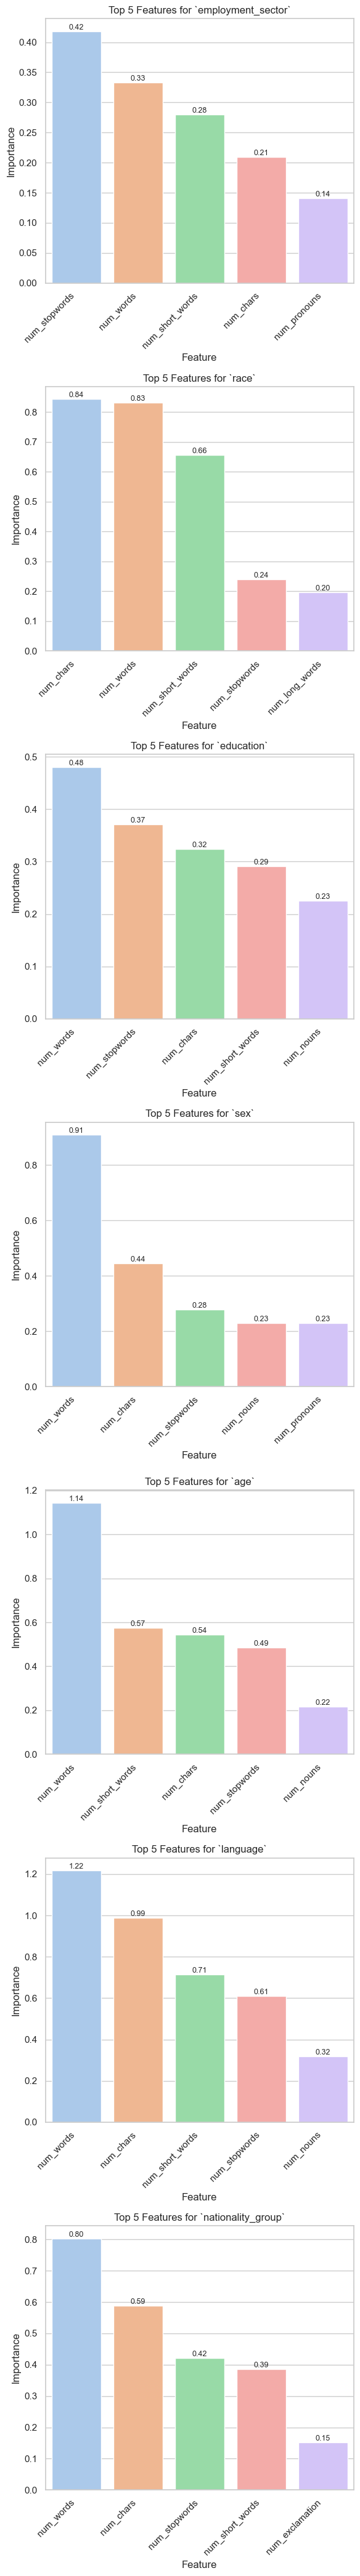

In [ ]:
fig, axes = plt.subplots(num_targets, 1, figsize=(6, 6*num_targets), sharey=False)

if num_targets == 1:
    axes = [axes]  # Make it iterable if only 1 target

for ax, target in zip(axes, targets):
    df_target = plot_df[plot_df['Target'] == target].sort_values('Importance', ascending=False)
    
    sns.barplot(
        data=df_target,
        x='Feature',
        y='Importance',
        hue='Feature',
        ax=ax,
        palette="pastel",
        legend=False
    )
    
    # Annotate bars
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f"{height:.2f}",
                    (p.get_x() + p.get_width()/2, height),
                    ha='center', va='bottom',
                    fontsize=9)
    
    ax.set_title(f"Top 5 Features for `{target}`")
    ax.set_xlabel("Feature")
    ax.set_ylabel("Importance")
    ax.set_xticks([i for i in range(len(ax.get_xticklabels()))])
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()